<a href="https://colab.research.google.com/github/Annette-1/SIMULACION-II/blob/main/Modelo_SIR_con_PyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <span style="color:brown;">**Modelo SIR: Ajuste de parámetros del modelo SIR**</span>
<span style="color:purple;"></span>

<span style="color:blue;">**Nombre: Jerónimo López Annette Michelle**</span>

<span style="color:blue;"> **Objetivo:** </span> *Estimar los parámetros $a$ (tasa de transmisión) y $b$ (tasa de recuperación) del modelo SIR que mejor describen el brote de influenza en un internado de $N=763$ alumnos.
Aplicando inferencia bayesiana mediante PyMC para calibrar un modelo epidemiológico SIR a partir de datos observados.usando PyMC*


¿Qué cambia respecto a la práctica anterior?

En la práctica anterior se minimizó $\chi^2$ con Metropolis-Hastings suponiendo $\sigma_i=1$. Aquí se usa una <span style="Sepia;">**verosimilitud normal**</span>:
$$I_{obs}(t_i)\sim N\big(I_{modelo}(t_i;a,b),\,\sigma^2\big)$$.

Su logaritmo es $-\frac{\chi^2}{(2\sigma^2)}+ c \quad(\text{constante})$, así que el punto más probable es el mismo que el de mínimos cuadrados. Las diferencias son:


| Práctica anterior | Esta práctica (PyMC) |
|---|---|
| $\sigma_i=1$ fija | $\sigma$ se **estima** a partir de los datos |
| Sin información a priori | Distribuciones **a priori** para $R_0$, $b$, $\sigma$ |
| Metropolis-Hastings de caminata aleatoria| NUTS (muestreador con gradientes) de PyMC |
| Parámetros $(a,b)$ | Parámetros $(R_0,b)$; $a$ se obtiene como $a=\frac{R_0\,b}{N}$ |

 <span style="Sepia;">**Del artículo conservamos**</span> la idea central de poner la prior sobre $R_0$ (que tiene una interpretación simple) y sobre la tasa de recuperación $b$, y derivar de ahí la tasa de transmisión.


 ## <span style="brown;"> **El modelo SIR**
 </span>

El modelo **SIR** consiste en tres Ecuacuiones Diferenciales Ordinarias No Lineales, no tiene una solucion analiticamente explicita. Es basicamente un modelo de enfermedades infecciosas.
Consiste en:
$$\frac{dS}{dt}=-aSI$$
$$\frac{dI}{dt}=aSI-bI$$
$$\frac{dR}{dt}=bI$$
donde
* $S=S(t)$ es susceptible
* $I(t)$ es infectado
* $R(t)$ es recuperado
* $a$ es la tasa de transmisión
* $b$ es la tasa de recuperación promedio

En cualquier momento, la población total es  $N = S + I + R$ y permanece constante como $N = S+ I+ R = 0$, donde el punto superior
indica la derivada con respecto al tiempo $t$, basta resolver las ecuaciones de $S$ e $I$ y obtener $R$ por diferencia.

El número reproductivo es $R_0=\frac{aN}{b}$.

### <span style="brown;">**Librerías PyMC**
</span>

>Para usarlas se cargan las herramientas.
>* `pymc`la cual arma el modelo y hace el muestreo.
>* `DifferentialEquation` conecta una EDO con PyMC.
>* `arviz` analiza los resultados.
>* `odeint` resuelve la EDO directamente (se usa para graficar)
>*  `numpy`/`matplotlib` hacen el cálculo y las figuras.

In [9]:
import arviz as az                           # análisis y gráficas de resultados bayesianos
import matplotlib.pyplot as plt              # gráficas
import numpy as np                           # arreglos numéricos
import pymc as pm                            # modelado probabilístico y muestreo MCMC (NUTS)
from pymc.ode import DifferentialEquation    # permite usar una EDO dentro de un modelo de PyMC
from scipy.integrate import odeint           # resuelve la EDO "a mano" (gráficas y verificación)

az.style.use("arviz-darkgrid")               # estilo de las gráficas

### <span style="brown;"> **Datos del artículo**
</span>


Se plantea este problema para un conjunto de datos a un brote de gripe en un internado. Estos datos se citaron por primera vez en  y se reproducen en la tabla siguiente;la solución obtenida por Murray. Según, los valores de los parámetros a y b son los siguientes: $a ≈ 0.00218$ y $b ≈ 0.4485$.


<span style="color:green;">**Tabla de datos de Influenza en una escuela**</span>

$
\boxed{
\begin{array}{lc}
\text{t} & 0 &  1& 2 & 3 & 4 & 5 & 6 & 7 & 8 & 9 & 10 & 11 &  12 & 13 & 14   \\
\hline
\text{$I(t)$} & 1& 3& 6& 25& 73& 222&294 &258 &237 &191 & 125 &69 & 27 & 11& 4\\
\end{array}
}
$

Procedemos a guardar los datos de la tabla. El **día 0 es la condición inicial **(1 infectado), que se conoce, así que lo que se le pide explicar al modelo son los días 1 a 14.

In [10]:
# ---- Datos del brote de influenza en el internado ----
N = 763                                                   # población total (alumnos)
t_datos = np.arange(0, 15)                                # días 0, 1, ..., 14
I_datos = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

# El día 0 (I = 1) es la condición inicial, que se conoce.
# Los datos que el modelo debe explicar son los de los días 1 a 14.
t_obs = t_datos[1:]
I_obs = I_datos[1:]

Procedmos a escribir las <span style="color:magenta;">**Ecuaciones diferenciales del modelo SIR**</span> para ello nos apoyamos de lo siguiente>

> *  `SIR(y, t, p)` es el lado derecho de las EDO.
> * `odeint` y `DifferentialEquation`: reciben el estado `y=[S, I]`, el tiempo `t` y los parámetros `p=(a, b)`, y se devolveran las derivadas.
> * Las condiciones iniciales son $S(0)=762$ e $I(0)=1$.

In [11]:
# ---- Ecuaciones del modelo SIR (solo S e I) ----
def SIR(y, t, p):
    """y = [S, I]  y  p = (a, b).  R no se calcula aparte: R = N - S - I."""
    dS = -p[0] * y[0] * y[1]                  # susceptibles que se infectan
    dI = p[0] * y[0] * y[1] - p[1] * y[1]     # nuevos infectados menos recuperados
    return [dS, dI]

y0 = [N - 1.0, 1.0]                           # condiciones iniciales: S(0) = 762, I(0) = 1

Graficaremos lo siguiente lo cual llamaré <span style="color:purple;">**Figura 1 (datos y curva de referencia).**</span> Antes de hacer inferencia comprobamos que la EDO está bien escrita: con los parámetros de Murray se debe reproducir la forma de los datos.

Modelo (Murray): pico de ≈ 288 infectados hacia el día 6.4
Datos:           pico de  294 infectados en el día 6


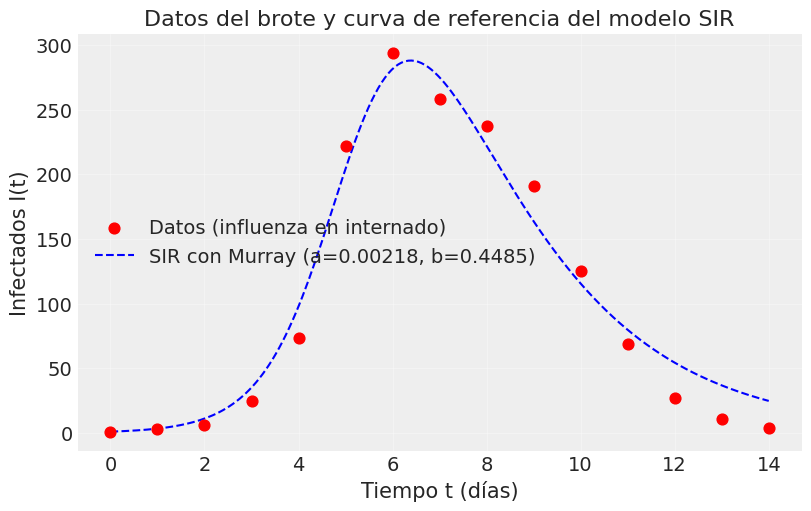

In [12]:
# ---- Figura 1: datos y curva del SIR con los parámetros de Murray ----
a_murray, b_murray = 0.00218, 0.4485
t_fino = np.linspace(0, 14, 200)
curva_murray = odeint(SIR, y0, t_fino, args=((a_murray, b_murray),), rtol=1e-8)

print(f"Modelo (Murray): pico de ≈ {curva_murray[:, 1].max():.0f} infectados "
      f"hacia el día {t_fino[curva_murray[:, 1].argmax()]:.1f}")
print(f"Datos:           pico de  {I_datos.max()} infectados en el día {t_datos[I_datos.argmax()]}")

plt.figure(figsize=(8, 5))
plt.scatter(t_datos, I_datos, color="red", s=60, zorder=5, label="Datos (influenza en internado)")
plt.plot(t_fino, curva_murray[:, 1], "b--", label=f"SIR con Murray (a={a_murray}, b={b_murray})")
plt.xlabel("Tiempo t (días)")
plt.ylabel("Infectados I(t)")
plt.title("Datos del brote y curva de referencia del modelo SIR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

<span style="color:teal;">**Interpretación de la Figura 1.**</span> El brote es corto y marcado: de 1 infectado se llega a un máximo de **294 en el día 6**, y después baja hasta 4 en el día 14. La curva del SIR con los parámetros de Murray tiene la misma forma de campana, con pico de $≈ 288$ hacia el día 6.4. Por lo que comprobé que la EDO está bien y el modelo es una descripción razonable del brote.

## <span style="color:brown;"> **Transfromación de La EDO dentro del entorno de PyMC**
</span>

Con el uso de la libreria de  `DifferentialEquation` convertimos la función `SIR` en un objeto que PyMC puede usar dentro de un modelo.

Con él, PyMC resuelve la EDO cada vez que se prueba un valor de $(a,b)$ y también calcula la sensibilidad de la solución respecto a los parámetros (los gradientes que necesita NUTS).

* `func`: la función de las EDO.
* `times`: tiempos donde se quiere la solución (días 1 a 14, sin el tiempo inicial).
* `n_states=2`: variables de estado (S e I). `n_theta=2`: parámetros (a y b).
* `t0=0`: instante en que se dan las condiciones iniciales.

In [13]:
# ---- Objeto DifferentialEquation de PyMC ----
sir_model = DifferentialEquation(
    func=SIR,                      # función que define las EDO
    times=t_obs.astype(float),     # tiempos en los que se quiere la solución (sin t0)
    n_states=2,                    # número de variables de estado: S e I
    n_theta=2,                     # número de parámetros de la EDO: a y b
    t0=0,                          # tiempo inicial (donde se da y0)
)

## <span style="color:brown;">**Modelo bayesiano**
</span>

Definimos las distribuciones a priori y la verosimilitud

| Elemento | Distribución | Por qué |
|---|---|---|
| $\sigma$ | HalfNormal(50) | Error típico de los datos, positivo. Prior débil: admite errores desde unos pocos hasta ~100 infectados. |
| $R_0$ | Normal(2, 3) truncada en $R_0>1$ | Como el artículo: sabemos que hubo epidemia, lo que implica $R_0>1$. |
| $b$ | LogNormal($\ln0.5$, 1) | Debe ser positiva; mediana de 0.5 por día (infección de ~2 días); rango a priori 95 % ≈ 0.07 a 3.5. |
| $a$ | $a=\frac{R_0\,b}{N}$ | Se deriva de $R_0$ y $b$, porque $R_0=\frac{aN}{b}$. |
| $I_{obs}$ | Normal($I_{modelo}$, $\sigma$) | Los datos varían alrededor de la curva del modelo. |

Es más fácil dar una prior razonable a $R_0$ (cuántas personas contagia un infectado) que a la tasa $a$, cuya escala depende de $N$. Por eso parametrizamos con $R_0$ y $b$.

In [14]:
# ---- Modelo bayesiano ----
with pm.Model() as modelo_sir:
    # (1) Error típico de los datos (en número de infectados), también se estima
    sigma = pm.HalfNormal("sigma", 50)

    # (2) Número reproductivo: acotado por abajo en 1 porque sabemos que hubo epidemia
    R0 = pm.TruncatedNormal("R0", mu=2, sigma=3, lower=1)

    # (3) Tasa de recuperación b (por día): positiva, mediana a priori 0.5 por día
    b = pm.LogNormal("b", mu=np.log(0.5), sigma=1)

    # (4) Tasa de transmisión a, derivada de R0 y b:  R0 = a·N / b  =>  a = R0·b / N
    a = pm.Deterministic("a", R0 * b / N)

    # (5) Solución del SIR para (a, b): matriz de 14 filas (días) x 2 columnas (S, I)
    curvas = sir_model(y0=y0, theta=[a, b])
    I_modelo = curvas[:, 1]                    # nos quedamos con la columna de infectados

    # (6) Verosimilitud: los infectados observados se distribuyen normal alrededor del modelo
    pm.Normal("I_obs", mu=I_modelo, sigma=sigma, observed=I_obs)

Para el <span style="color:purple;">**Muestreo**</span> usmaos `pm.sample` la cual obtiene muestras de la distribución posterior de $(R_0,b,\sigma)$ con NUTS.

* `tune=1000`: iteraciones de calentamiento, en que el muestreador se ajusta y que luego se descartan (equivale al *burn-in*).
* `1000` es el número de muestras que se guardan por cadena; `chains=2` corre dos cadenas independientes, para comprobar que llegan a lo mismo.
* `target_accept=0.9`: pasos más cuidadosos, para evitar divergencias.
* `cores=1`: las cadenas se corren una tras otra (más estable con `DifferentialEquation`).

> **Tiempo:** resolver una EDO en cada paso es lento. El ejemplo del artículo tardó 5339 s con 2 cadenas. Este modelo es más pequeño (14 tiempos), pero puede tardar varios minutos.

In [15]:
# ---- Muestreo (puede tardar varios minutos) ----
with modelo_sir:
    idata = pm.sample(500, tune=500, chains=2, cores=1,
                      target_accept=0.9, random_seed=42)

Output()

Para analizar la convergencia comprobamos que el muestreo funciono con ellos nos apoyamos de lo siguiente:


> * `az.summary` da media, desviación, intervalo del 95 % y dos diagnósticos: **$\hat R$** (debe ser ≈ 1.00, y menor que 1.01) y el tamaño efectivo de muestra **ESS** (cientos o más).
> * Las **transiciones divergentes** deben ser 0.
> * Graficamos y la llamaré **Figura 2:** a la izquierda, la distribución de cada parámetro por cadena; a la derecha, la traza.

         mean     sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd  ess_bulk  \
R0      3.736  0.144     3.465      4.046      0.008    0.007     318.0   
b       0.446  0.019     0.410      0.485      0.001    0.001     314.0   
a       0.002  0.000     0.002      0.002      0.000    0.000     958.0   
sigma  21.234  5.080    12.849     31.499      0.260    0.232     421.0   

       ess_tail  r_hat  
R0        257.0    1.0  
b         246.0    1.0  
a         544.0    1.0  
sigma     504.0    1.0  

Transiciones divergentes: 0


/tmp/ipykernel_1301/2490527014.py:10: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


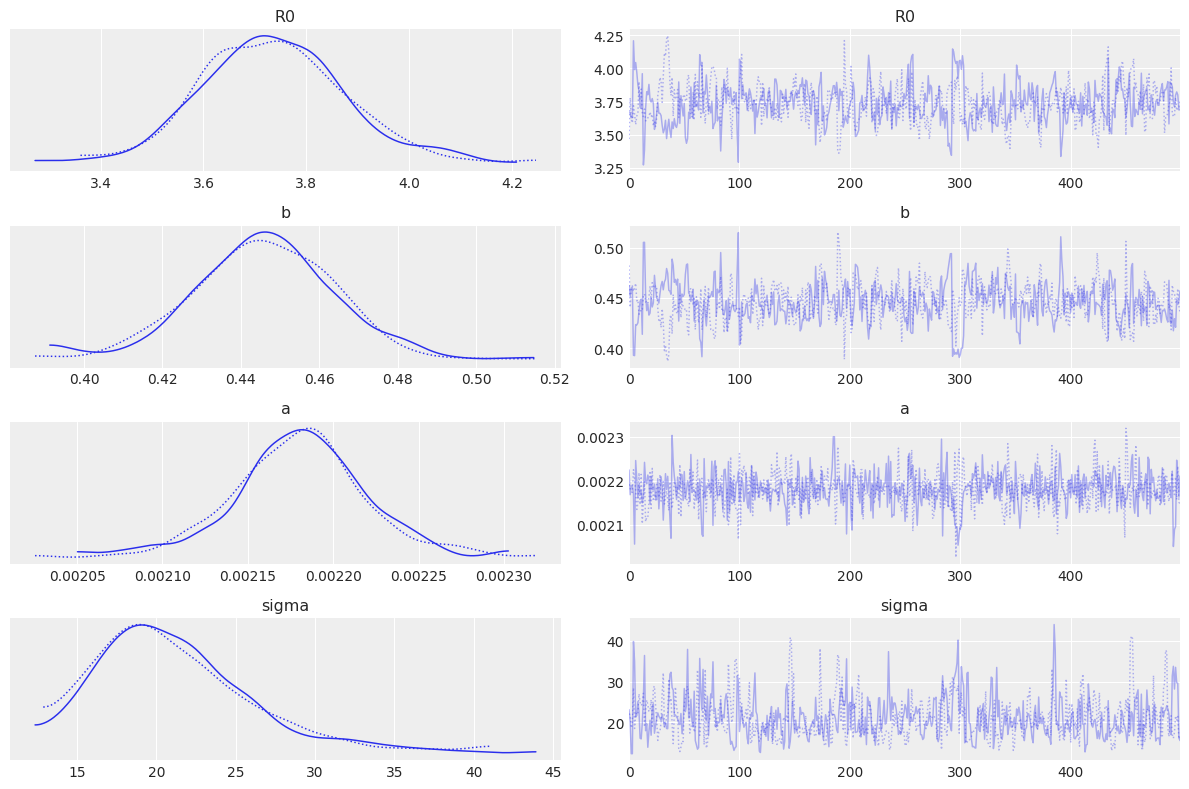

In [16]:
# ---- Diagnóstico de convergencia ----
resumen = az.summary(idata, var_names=["R0", "b", "a", "sigma"], hdi_prob=0.95)
print(resumen)

n_div = int(idata.sample_stats["diverging"].sum())
print(f"\nTransiciones divergentes: {n_div}")

# ---- Figura 2: trazas de las cadenas y distribuciones por cadena ----
az.plot_trace(idata, var_names=["R0", "b", "a", "sigma"])
plt.tight_layout()
plt.show()

<span style="color:teal;">**Interpretación de la Figura 2.**</span>

* Las dos cadenas se **superponen** en las distribuciones de la izquierda.
* Las trazas de la derecha parecen estables alrededor de un valor constante, sin tendencias ni tramos pegados.
* NO hay ninguna divergencia.


*Detalle:* $R_0$ y $b$ están **fuertemente correlacionados**

Para las <span style="color:magenta;">**Distribuciones posteriores**</span>
juntamos las cadenas y se grafica la distribución posterior de $R_0$, $b$, $a$ y $\sigma$, con su media y el intervalo de credibilidad del 95 %.

/tmp/ipykernel_1301/2407661050.py:21: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


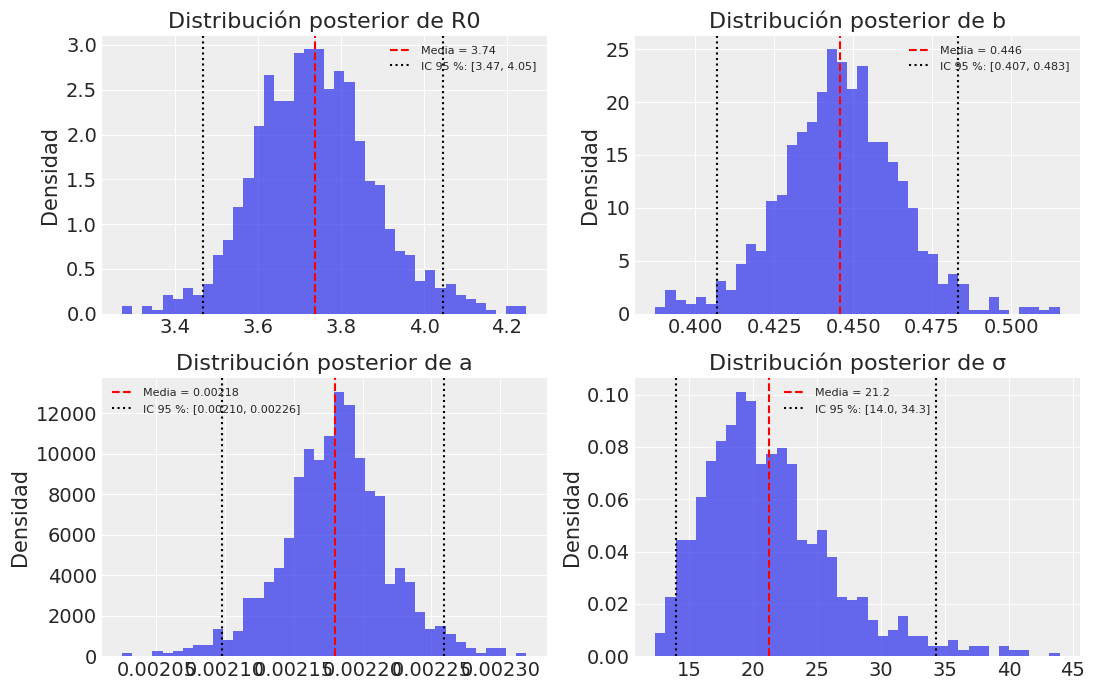

Correlación posterior entre R0 y b: -0.91


In [17]:
# ---- Muestras posteriores (se juntan las cadenas en un solo vector por parámetro) ----
post = idata.posterior
R0_s = post["R0"].values.flatten()
b_s = post["b"].values.flatten()
a_s = post["a"].values.flatten()
sigma_s = post["sigma"].values.flatten()

# ---- Figura 3: distribuciones posteriores con media e intervalo de credibilidad del 95 % ----
parametros = [("R0", R0_s, ".2f"), ("b", b_s, ".3f"), ("a", a_s, ".5f"), ("σ", sigma_s, ".1f")]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (nombre, v, fmt) in zip(axes.ravel(), parametros):
    lo, hi = np.percentile(v, [2.5, 97.5])
    ax.hist(v, bins=40, density=True, alpha=0.7)
    ax.axvline(v.mean(), color="red", linestyle="--", label=f"Media = {v.mean():{fmt}}")
    ax.axvline(lo, color="black", linestyle=":", label=f"IC 95 %: [{lo:{fmt}}, {hi:{fmt}}]")
    ax.axvline(hi, color="black", linestyle=":")
    ax.set_title(f"Distribución posterior de {nombre}")
    ax.set_ylabel("Densidad")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Correlación posterior entre R0 y b: {np.corrcoef(R0_s, b_s)[0, 1]:.2f}")

### <span style="color:brown;"> **Ajuste del modelo con incertidumbre**
</span>

Tomamos 300 muestras posteriores de $(a,b)$ y con cada una se resuelve el SIR, lo que da 300 curvas posibles. Su dispersión muestra cuánta incertidumbre hay en la curva. Se agrega una segunda banda que además suma el ruido de observación $N(0,\sigma^2)$, que indica dónde se esperaría que caigan los datos observados.

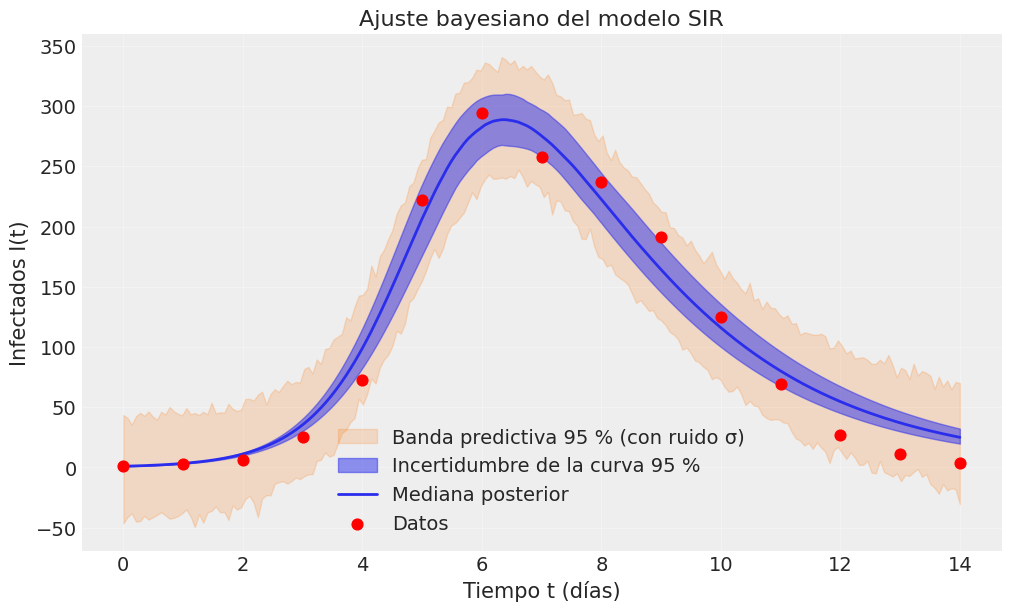

In [18]:
# ---- Figura 4: ajuste del modelo con incertidumbre ----
rng = np.random.default_rng(0)
idx = rng.choice(len(a_s), size=min(300, len(a_s)), replace=False)   # 300 muestras posteriores al azar

# Una curva de infectados por cada muestra posterior (a, b)
curvas_post = np.array([odeint(SIR, y0, t_fino, args=((a_s[i], b_s[i]),), rtol=1e-8)[:, 1]
                        for i in idx])
# Lo mismo, pero sumando el ruido de observación N(0, σ): banda "predictiva"
curvas_pred = curvas_post + rng.normal(0, sigma_s[idx][:, None], size=curvas_post.shape)

I_med = np.median(curvas_post, axis=0)
mu_lo, mu_hi = np.percentile(curvas_post, [2.5, 97.5], axis=0)
pr_lo, pr_hi = np.percentile(curvas_pred, [2.5, 97.5], axis=0)

plt.figure(figsize=(10, 6))
plt.fill_between(t_fino, pr_lo, pr_hi, color="C1", alpha=0.2, label="Banda predictiva 95 % (con ruido σ)")
plt.fill_between(t_fino, mu_lo, mu_hi, color="C0", alpha=0.5, label="Incertidumbre de la curva 95 %")
plt.plot(t_fino, I_med, color="C0", linewidth=2, label="Mediana posterior")
plt.scatter(t_datos, I_datos, color="red", s=60, zorder=5, label="Datos")
plt.xlabel("Tiempo t (días)")
plt.ylabel("Infectados I(t)")
plt.title("Ajuste bayesiano del modelo SIR")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

<span style="color:teal;">**Interpretación de la Figura 4.**<span>
* La **mediana posterior** reproduce el crecimiento, el pico  y la bajada.
* La banda azul (incertidumbre de la curva) es angosta: los datos determinan bien la curva promedio.
* La banda naranja (predictiva) es mucho más ancha, porque incluye el ruido σ. Con los valores de referencia, **los 14 datos caen dentro de la banda del 95 %**, es decir, el modelo describe los datos de forma coherente.
* Hay un patrón que el modelo no captura: los datos de los días 12 a 14 quedan **sistemáticamente por debajo** de la curva (el SIR baja más lento que el brote real). Un buen ajuste tendría residuos sin patrón, así que esto muestra una limitación del modelo (recuperación constante, población homogénea) y no del método de inferencia.
* La banda predictiva llega a valores negativos en los primeros y en los últimos días: la verosimilitud normal admite infectados negativos.

Finalmente calculamos el <span style="color:magenta;">**Número reproductivo, máximo de infectados y comparación**</span> dado que la posterior de $R_0$ es una distribución, el máximo de infectados $I_{max}=N\left[1-\frac{1+\ln R_0}{R_0}\right]$ también lo es, y se calcula con cada muestra. Al final se comparamos con Murray y con el método $\chi^2$ + Metropolis-Hastings propio de la práctica anterior.

In [19]:
 #---- Máximo de infectados a partir de R0 ----
Imax_s = N * (1 - (1 + np.log(R0_s)) / R0_s)      # I_max = N·[1 - (1 + ln R0)/R0]
print(f"R0    = {R0_s.mean():.2f}   IC 95 %: [{np.percentile(R0_s, 2.5):.2f}, {np.percentile(R0_s, 97.5):.2f}]")
print(f"I_max = {Imax_s.mean():.0f} personas   IC 95 %: [{np.percentile(Imax_s, 2.5):.0f}, {np.percentile(Imax_s, 97.5):.0f}]")
print(f"Máximo observado en los datos: {I_datos.max()} personas")

# ---- Comparación con los otros métodos (valores de la práctica anterior) ----
print("\nMétodo                     a           b        R0")
print(f"Murray                  0.002180    0.4485    {0.00218 * N / 0.4485:.2f}")
print(f"χ² + MH (propio)        0.002181    0.4452    {0.002181 * N / 0.4452:.2f}")
print(f"PyMC (media posterior)  {a_s.mean():.6f}    {b_s.mean():.4f}    {R0_s.mean():.2f}")

R0    = 3.74   IC 95 %: [3.47, 4.05]
I_max = 289 personas   IC 95 %: [269, 311]
Máximo observado en los datos: 294 personas

Método                     a           b        R0
Murray                  0.002180    0.4485    3.71
χ² + MH (propio)        0.002181    0.4452    3.74
PyMC (media posterior)  0.002180    0.4459    3.74


## <span style="color:purple;">**Conclusión**</span>

* El modelo SIR bayesiano en PyMC (EDO + priors + verosimilitud normal) estima $R_0\approx3.7$, $b\approx0.45$ por día ($\approx2$ días de infección) y $a\approx0.0022$, con intervalos de credibilidad.
* La convergencia se comprueba con $\hat R$, el ESS, las divergencias y las trazas; solo después se interpretan los resultados.
* Las estimaciones coinciden con Murray y con el ajuste $\chi^2$ + Metropolis-Hastings, lo que valida los tres métodos. La ventaja del enfoque bayesiano está en cuantificar la incertidumbre y estimar $\sigma$, sin fijarla.
* El máximo de infectados que se predice (≈ 289) concuerda con el observado (294); estimar los parámetros permite anticipar el tamaño del pico, útil para decisiones de salud pública.

<span style="color:red;">**Limitaciones**</span>
* El SIR simple sobrestima los últimos días del brote (residuos con patrón en los días 12 a 14).
* La verosimilitud normal con $\sigma$ constante admite valores negativos y no depende del nivel de $I(t)$; para conteos convendría una binomial negativa o un error proporcional al nivel.
* `DifferentialEquation` es lento comparado con otros resolvedores (existen alternativas más rápidas, como `sunode`).
* Las priors son débiles; con pocos datos podrían influir más, y conviene revisar su efecto cambiándolas.